# AI-Generated Image Detection Using DINOv3

**Goal:** classify images as *real* or *AI-generated* using features from a **frozen DINOv3** model plus lightweight classifiers, then test how well the result transfers to a different dataset (CIFAKE).

### Project stages

| Stage | What happens |
|---|---|
| 1. Setup | Install and import libraries, select the device, log in to Hugging Face, load DINOv3, set paths |
| 2. Dataset exploration | Inspect folders, CSV files, labels and image properties |
| 3. Data preparation | Build the image/label table, check labels and shortcuts, split into train/val/test |
| 4. Feature extraction | Pass every image through frozen DINOv3 and save the feature vectors |
| 5. Classifier training | Train a dummy baseline, logistic regression and a PyTorch linear classifier |
| 6. Evaluation | Test-set metrics, shuffled-label control, error analysis |
| 7. Transfer test (CIFAKE) | Apply the trained model to a different dataset, without retraining |
| 8. Results & final report | Summary table, figures and key findings |
| Optional | Identify *which AI generator* produced an image (exploratory) |

# Stage 1: Setup
Install and import the libraries, check the device, log in to Hugging Face, load the frozen DINOv3 model and define the project paths.

### 1.1 Install and import libraries
Install the Hugging Face libraries, then import every tool used in the notebook (once) and fix the random seed.

In [1]:
# Stage 1.1 - Install the required Hugging Face libraries (quiet mode)
!pip install -q "transformers>=4.56.0" accelerate

In [2]:
# Stage 1.1 - Imports (every library used in the notebook is imported here, once)

# --- Standard library ---
import os                              # file system access (paths, folders)
import re                              # text patterns (used in the optional generator task)
import time                            # timing the feature extraction
import copy                            # copy the best classifier weights
import random                          # random sampling
from collections import Counter        # count files per extension

# --- Data and numerical tools ---
import numpy as np                     # arrays and math
import pandas as pd                    # tables (DataFrames)

# --- Images and plots ---
from PIL import Image                  # open and read images
import matplotlib.pyplot as plt        # plots
import seaborn as sns                  # nicer plots (confusion matrices)

# --- PyTorch ---
import torch                           # tensors and GPU support
import torch.nn as nn                  # neural network layers and losses
from torch.utils.data import Dataset, DataLoader, TensorDataset   # batching tools

# --- Hugging Face (loads the pretrained DINOv3 and its image processor) ---
import transformers
from transformers import AutoImageProcessor, AutoModel

# --- scikit-learn: splitting, scaling, classifiers and metrics ---
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# --- Progress bars ---
from tqdm.auto import tqdm

# --- Reproducibility: a fixed seed gives the same results on every run ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("All libraries imported successfully!")

All libraries imported successfully!


### 1.2 Device check
Show the library versions and whether a GPU is available.

In [3]:
# Stage 1.2 - Check the environment (GPU + library versions)
# A "tensor" is PyTorch's array type (like a NumPy array, but it can run on a GPU).
# torch.cuda.is_available() tells us whether a GPU can be used.
print("PyTorch version      :", torch.__version__)
print("Transformers version :", transformers.__version__)
print("GPU available        :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name             :", torch.cuda.get_device_name(0))

# 'device' is where tensors and the model will live: GPU if possible, else CPU.
# Every tensor must be on the same device as the model that uses it.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device         :", device)

PyTorch version      : 2.11.0+cu130
Transformers version : 5.20.2
GPU available        : True
GPU name             : Tesla T4
Using device         : cuda


### 1.3 Hugging Face login
Read the `HF_TOKEN` secret from Kaggle Secrets (needed to download DINOv3).

In [4]:
# Stage 1.3 - Get the Hugging Face token from Kaggle Secrets
# Import Kaggle's secret manager
from kaggle_secrets import UserSecretsClient

# Access Kaggle Secrets
secrets = UserSecretsClient()

# Retrieve the Hugging Face token
hf_token = secrets.get_secret("HF_TOKEN")

# Confirm that the token was retrieved
if hf_token:
    print("Hugging Face authentication token retrieved!")
else:
    raise ValueError("HF_TOKEN was not found!")

Hugging Face authentication token retrieved!


### 1.4 Load the frozen DINOv3 model
- The **processor** resizes and normalizes images the way DINOv3 expects.
- All model weights are **frozen** and the model is in `eval()` mode: it only extracts features, nothing is trained here.
- Only a lightweight classifier is trained on top of these features (Stages 5-6).

In [5]:
# Stage 1.4 - Load the pretrained DINOv3 model and its image processor
# Define the exact pretrained DINOv3 model
MODEL_NAME = "facebook/dinov3-vits16-pretrain-lvd1689m"

# Load the image processor
processor = AutoImageProcessor.from_pretrained(
    MODEL_NAME,
    token=hf_token
)

# Load the pretrained DINOv3 model
model = AutoModel.from_pretrained(
    MODEL_NAME,
    token=hf_token
)

# Move the model to the available device
model = model.to(device)

# Freeze all pretrained model parameters
for parameter in model.parameters():
    parameter.requires_grad = False

# Set the model to evaluation mode
model.eval()

print("DINOv3 loaded successfully!")
print("Model:", MODEL_NAME)
print("Device:", device)

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

DINOv3 loaded successfully!
Model: facebook/dinov3-vits16-pretrain-lvd1689m
Device: cuda


### 1.5 Project settings
Dataset paths, column names and the label convention used in the rest of the notebook.

In [6]:
# Stage 1.5 - Project settings (paths and label convention)

# Folder where Kaggle mounted the main dataset
DATA_ROOT = "/kaggle/input/datasets/alessandrasala79/ai-vs-human-generated-dataset"
TRAIN_FOLDER = os.path.join(DATA_ROOT, "train_data")   # training images
TRAIN_CSV = os.path.join(DATA_ROOT, "train.csv")       # image names + labels (the test CSV has no labels)

# Column names inside train.csv
IMAGE_COL = "file_name"
LABEL_COL = "label"

# Label convention: 0 = real, 1 = AI-generated (confirmed visually in Stage 3.2)
LABEL_MAP = {0: 0, 1: 1}

# Image file extensions accepted by the notebook
IMG_EXT = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

# Stage 2: Dataset exploration
Look at the data before using it: folder structure, CSV files, label counts and image properties (format, size, corrupted files).

### 2.1 Folder structure
List the dataset folders and count files per type.

In [7]:
# Stage 2.1 - Explore the folder structure
# Safety check: stop with a clear message if the path is wrong
print("Root exists:", os.path.exists(DATA_ROOT))

# os.listdir returns the names of everything directly inside a folder
print("\nTop-level content of the dataset:")
for name in sorted(os.listdir(DATA_ROOT)):
    full_path = os.path.join(DATA_ROOT, name)          # build the full path
    kind = "FOLDER" if os.path.isdir(full_path) else "FILE"
    print(f"  [{kind}] {name}")

# os.walk visits every folder and subfolder.
# For each one it gives: (current folder, its subfolders, its files).
# We count files by extension (.jpg, .png, .csv ...) for each main folder.
print("\nFile counts by extension, per folder:")
for name in sorted(os.listdir(DATA_ROOT)):
    full_path = os.path.join(DATA_ROOT, name)
    if not os.path.isdir(full_path):
        continue                                       # skip plain files here

    ext_counter = Counter()                            # extension -> number of files
    subfolders = set()                                 # names of subfolders we meet
    for current_dir, dirs, files in os.walk(full_path):
        if current_dir != full_path:
            subfolders.add(os.path.relpath(current_dir, full_path))
        for f in files:
            ext = os.path.splitext(f)[1].lower()       # e.g. ".jpg"
            ext_counter[ext] += 1

    print(f"\n  {name}: {sum(ext_counter.values())} files")
    print(f"    extensions : {dict(ext_counter)}")
    # If images are split into class subfolders, they will show up here
    print(f"    subfolders : {sorted(subfolders)[:10] if subfolders else 'none (flat folder)'}")

Root exists: True

Top-level content of the dataset:
  [FILE] test.csv
  [FOLDER] test_data_v2
  [FILE] train.csv
  [FOLDER] train_data

File counts by extension, per folder:

  test_data_v2: 5540 files
    extensions : {'.jpg': 5540}
    subfolders : none (flat folder)

  train_data: 79950 files
    extensions : {'.jpg': 79950}
    subfolders : none (flat folder)


### 2.2 Metadata (CSV) files
Load each CSV and check its columns, size and missing values.

In [8]:
# Stage 2.2 - Find and inspect the CSV / metadata files
# Walk through the whole dataset and collect every .csv path
csv_files = []
for current_dir, dirs, files in os.walk(DATA_ROOT):
    for f in files:
        if f.lower().endswith(".csv"):
            csv_files.append(os.path.join(current_dir, f))

print("CSV files found:", csv_files)

# Dictionary that will hold each loaded table: {path: DataFrame}
tables = {}
for path in csv_files:
    df = pd.read_csv(path)
    tables[path] = df
    print("\n" + "=" * 70)
    print("File  :", path)
    print("Shape :", df.shape, "(rows, columns)")
    print("Columns and types:")
    print(df.dtypes)                                   # column names + data types
    print("\nFirst 5 rows:")
    print(df.head())                                   # preview, no assumptions
    print("\nMissing values per column:")
    print(df.isna().sum())                             # NaN count per column

CSV files found: ['/kaggle/input/datasets/alessandrasala79/ai-vs-human-generated-dataset/test.csv', '/kaggle/input/datasets/alessandrasala79/ai-vs-human-generated-dataset/train.csv']

File  : /kaggle/input/datasets/alessandrasala79/ai-vs-human-generated-dataset/test.csv
Shape : (5540, 1) (rows, columns)
Columns and types:
id    object
dtype: object

First 5 rows:
                                                  id
0  test_data_v2/1a2d9fd3e21b4266aea1f66b30aed157.jpg
1  test_data_v2/ab5df8f441fe4fbf9dc9c6baae699dc7.jpg
2  test_data_v2/eb364dd2dfe34feda0e52466b7ce7956.jpg
3  test_data_v2/f76c2580e9644d85a741a42c6f6b39c0.jpg
4  test_data_v2/a16495c578b7494683805484ca27cf9f.jpg

Missing values per column:
id    0
dtype: int64

File  : /kaggle/input/datasets/alessandrasala79/ai-vs-human-generated-dataset/train.csv
Shape : (79950, 3) (rows, columns)
Columns and types:
Unnamed: 0     int64
file_name     object
label          int64
dtype: object

First 5 rows:
   Unnamed: 0                   

### 2.3 Labels
Find the label column and count the images per class.

In [9]:
# Stage 2.3 - Look at the label-like columns in each table
# We do NOT assume which column is the label. For every column with few
# distinct values (<= 20) we print how often each value appears.
# A label column will show up here (e.g. two values for a binary task).
for path, df in tables.items():
    print("\n" + "=" * 70)
    print("File:", os.path.basename(path))
    for col in df.columns:
        n_unique = df[col].nunique()                   # number of distinct values
        if n_unique <= 20:
            print(f"\nColumn '{col}' has {n_unique} distinct values:")
            print(df[col].value_counts(dropna=False))  # count per value


File: test.csv

File: train.csv

Column 'label' has 2 distinct values:
label
1    39975
0    39975
Name: count, dtype: int64


### 2.4 Image checks and samples
Check formats, sizes and corrupted files on a random sample, then display a few images.

Total images found in train_data: 79950
Corrupted files in sample: 0
Formats: {'JPEG': 500}
Color modes: {'RGB': 500}
Top 5 (width, height) pairs:
width  height
768    512       271
512    768        66
768    496        43
       768        14
       576        13
dtype: int64


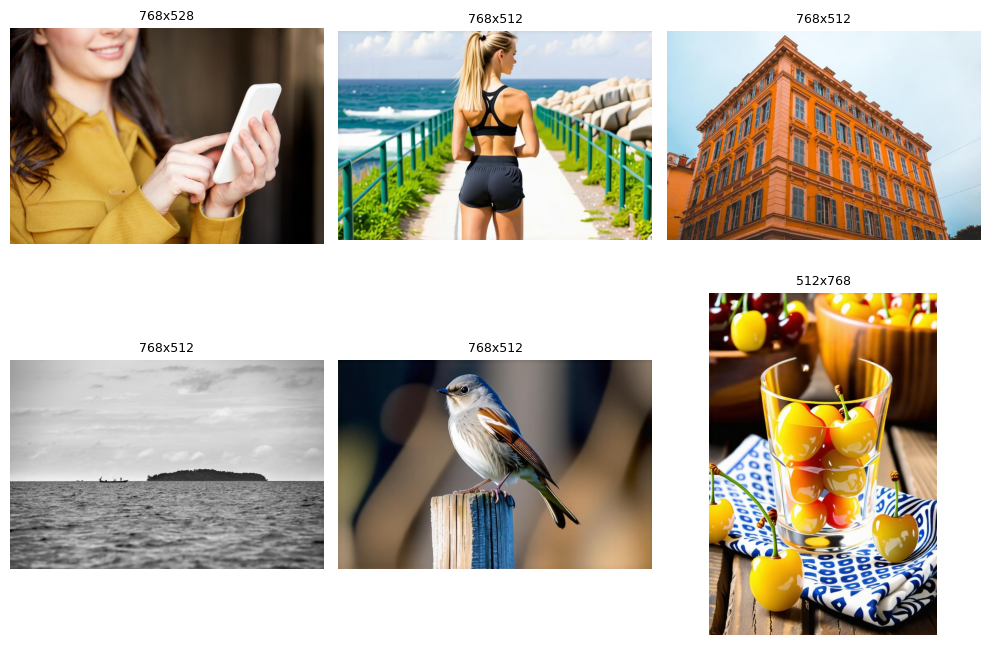

In [10]:
# Stage 2.4 - Check formats, sizes, modes and corrupted files, then show sample images
# Collect only the PATHS of all training images (cheap, no pixels loaded)
train_dir = TRAIN_FOLDER
all_images = []
for current_dir, dirs, files in os.walk(train_dir):
    for f in files:
        if f.lower().endswith(IMG_EXT):
            all_images.append(os.path.join(current_dir, f))
print("Total images found in train_data:", len(all_images))

# ----- Part A: statistics on a random sample of 500 images -----
random.seed(SEED)                                   # fixed seed -> reproducible statistics
stats_sample = random.sample(all_images, min(500, len(all_images)))

records, corrupted = [], []
for p in stats_sample:
    try:
        with Image.open(p) as img:
            img.verify()                          # integrity check
        with Image.open(p) as img:                # re-open: verify() invalidates the handle
            records.append({"format": img.format, "mode": img.mode,
                            "width": img.width, "height": img.height})
    except Exception as e:
        corrupted.append(p)

info = pd.DataFrame(records)
print("Corrupted files in sample:", len(corrupted))
print("Formats:", info["format"].value_counts().to_dict())
print("Color modes:", info["mode"].value_counts().to_dict())
print("Top 5 (width, height) pairs:")
print(info.groupby(["width", "height"]).size().sort_values(ascending=False).head(5))

# ----- Part B: display a few sample images -----
# Change this number and re-run the cell to see a different set of images
DISPLAY_SEED = 7
random.seed(DISPLAY_SEED)
display_sample = random.sample(all_images, 6)

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, path in zip(axes.flat, display_sample):
    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))             # convert to RGB only for display
        ax.set_title(f"{img.width}x{img.height}", fontsize=9)
    ax.axis("off")                                # hide axis ticks
plt.tight_layout()
plt.show()

# Stage 3: Data preparation
Build a clean table of image paths and labels, confirm what label 0/1 mean, check for shortcuts (for example image size differing between classes), then split the data 70/15/15 without leakage.

### 3.1 Image/label table
Build a table of paths and labels and check for duplicates, missing labels and missing files.

In [11]:
# Stage 3.1 - Build a clean table of (image path, label)
# Read train.csv. It has 3 columns: 'Unnamed: 0' (just a row index),
# 'file_name' (path relative to DATA_ROOT) and 'label' (0 or 1).
df = pd.read_csv(TRAIN_CSV)

# Keep only the two useful columns. The 'Unnamed: 0' column adds nothing.
df = df[[IMAGE_COL, LABEL_COL]].copy()
df = df.rename(columns={IMAGE_COL: "rel_path", LABEL_COL: "raw_label"})

# Convert the raw label (0/1) into our own numbering using LABEL_MAP.
# If a raw value was not in LABEL_MAP, .map() would give NaN, which we check below.
df["label"] = df["raw_label"].map(LABEL_MAP)

# Build the full path to every image so we can open it later.
df["path"] = df["rel_path"].apply(lambda p: os.path.join(DATA_ROOT, p))

# ----- Sanity checks (a safe pipeline checks its own assumptions) -----
print("Rows in table             :", len(df))
print("Duplicate file names      :", df["rel_path"].duplicated().sum())
print("Rows with missing label   :", df["label"].isna().sum())

# Does every path in the CSV really exist on disk?
exists = df["path"].apply(os.path.exists)
print("Files listed but not found:", (~exists).sum())

print("\nClass counts:")
print(df["label"].value_counts().sort_index())

df.head()

Rows in table             : 79950
Duplicate file names      : 0
Rows with missing label   : 0
Files listed but not found: 0

Class counts:
label
0    39975
1    39975
Name: count, dtype: int64


,rel_path,raw_label,label,path
0,train_data/a6dcb93f596a43249135678dfcfc17ea.jpg,1,1,/kaggle/input/datasets/alessandrasala79/ai-vs-...
1,train_data/041be3153810433ab146bc97d5af505c.jpg,0,0,/kaggle/input/datasets/alessandrasala79/ai-vs-...
2,train_data/615df26ce9494e5db2f70e57ce7a3a4f.jpg,1,1,/kaggle/input/datasets/alessandrasala79/ai-vs-...
3,train_data/8542fe161d9147be8e835e50c0de39cd.jpg,0,0,/kaggle/input/datasets/alessandrasala79/ai-vs-...
4,train_data/5d81fa12bc3b4cea8c94a6700a477cf2.jpg,1,1,/kaggle/input/datasets/alessandrasala79/ai-vs-...


### 3.2 Label and shortcut checks
View images of each class to confirm what 0 and 1 mean, and check that image size or file size does not differ between classes (a possible shortcut).

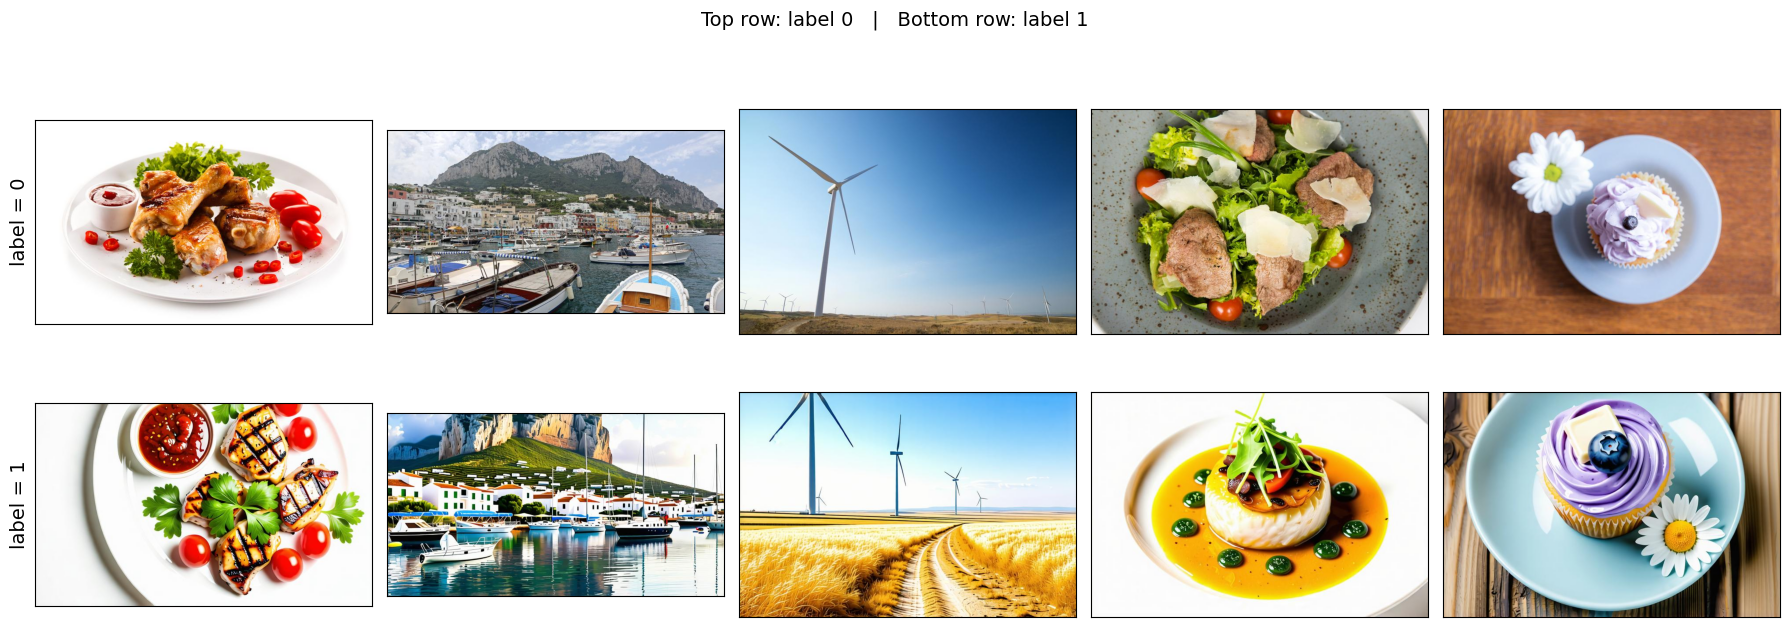

File size (KB) and dimensions per class:
label                    0            1
width   count  1000.000000  1000.000000
        mean    712.384000   712.384000
        std     104.373456   104.373456
        min     384.000000   384.000000
        25%     768.000000   768.000000
        50%     768.000000   768.000000
        75%     768.000000   768.000000
        max     768.000000   768.000000
height  count  1000.000000  1000.000000
        mean    571.088000   571.088000
        std     121.891007   121.891007
        min     144.000000   144.000000
        25%     512.000000   512.000000
        50%     512.000000   512.000000
        75%     720.000000   720.000000
        max     768.000000   768.000000
file_kb count  1000.000000  1000.000000
        mean     54.064236    59.830005
        std      26.686218    23.137702
        min      13.996094    11.035156
        25%      34.274414    42.748779
        50%      47.272461    56.470703
        75%      69.579346    74.290771

In [12]:
# Stage 3.2 - Verify the labels visually and check for shortcuts
# ===== PART 1: look at images from each class =====
# We take 5 random images per class. random_state makes the choice repeatable.
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for row, cls in enumerate([0, 1]):
    samples = df[df["label"] == cls].sample(5, random_state=SEED)
    for col, path in enumerate(samples["path"]):
        with Image.open(path) as img:
            axes[row, col].imshow(img.convert("RGB"))
    axes[row, 0].set_ylabel(f"label = {cls}", fontsize=14)
    for ax in axes[row]:
        ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Top row: label 0   |   Bottom row: label 1", fontsize=14)
plt.tight_layout()
plt.show()

# ===== PART 2: shortcut check =====
# A "shortcut" is a property that differs between classes for reasons
# unrelated to the real task (e.g. all AI images have a different size).
# A classifier can learn the shortcut instead of real AI artifacts, which
# would make our accuracy look better than it really is.
# We check image size and file size on 1000 random images per class.
# Image.open only reads the header here, so this is fast.
records = []
for cls in [0, 1]:
    subset = df[df["label"] == cls].sample(1000, random_state=SEED)
    for path in subset["path"]:
        with Image.open(path) as img:
            width, height = img.size
        records.append({
            "label": cls,
            "width": width,
            "height": height,
            "aspect_ratio": round(width / height, 2),
            "file_kb": os.path.getsize(path) / 1024,
        })
shortcut_df = pd.DataFrame(records)

print("File size (KB) and dimensions per class:")
print(shortcut_df.groupby("label")[["width", "height", "file_kb"]].describe().T)

print("\nMost common (width, height) per class, as % of the sample:")
for cls in [0, 1]:
    sub = shortcut_df[shortcut_df["label"] == cls]
    pct = (sub.groupby(["width", "height"]).size() / len(sub) * 100).round(1)
    print(f"\nLabel {cls}:")
    print(pct.sort_values(ascending=False).head(5))

### 3.3 Train / validation / test split
Stratified 70/15/15 split, with a check that no image appears in two splits.

In [13]:
# Stage 3.3 - Split into train / validation / test (70/15/15)
# Step 1: set aside 30% of the data, to be divided into validation and test.
#   stratify=df["label"] -> each split keeps the same real/AI proportion (50/50).
#   random_state=SEED    -> the same split every time we run this.
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=SEED
)

# Step 2: split that 30% in half -> 15% validation, 15% test.
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)

# ----- Report the result -----
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    counts = part["label"].value_counts().sort_index().to_dict()
    print(f"{name:5s}: {len(part):6d} images | class counts: {counts}")

# ----- Data-leakage check: no image may appear in two splits -----
train_set, val_set, test_set = set(train_df["path"]), set(val_df["path"]), set(test_df["path"])
print("\nOverlap train/val :", len(train_set & val_set))
print("Overlap train/test:", len(train_set & test_set))
print("Overlap val/test  :", len(val_set & test_set))

# Save the splits so that, if Kaggle restarts, we reuse the EXACT same split.
os.makedirs("/kaggle/working", exist_ok=True)
train_df.to_csv("/kaggle/working/train_split.csv", index=False)
val_df.to_csv("/kaggle/working/val_split.csv", index=False)
test_df.to_csv("/kaggle/working/test_split.csv", index=False)
print("\nSplits saved to /kaggle/working/")

train:  55965 images | class counts: {0: 27982, 1: 27983}
val  :  11992 images | class counts: {0: 5996, 1: 5996}
test :  11993 images | class counts: {0: 5997, 1: 5996}

Overlap train/val : 0
Overlap train/test: 0
Overlap val/test  : 0

Splits saved to /kaggle/working/


# Stage 4: Feature extraction
Pass each image through the frozen DINOv3 and keep one vector of 768 numbers per image (CLS token + mean of the patch tokens). Features are saved to disk, so they are computed only once.

### 4.1 Sanity check on one image
Run a single image through the processor and model to see the tensor shapes.

In [14]:
# Stage 4.1 - Sanity check on a single image
# Pick one image path from the list we built in Stage 2 (all_images).
# Seed 3 makes the choice reproducible.
random.seed(3)
img_path = random.choice(all_images)
image = Image.open(img_path).convert("RGB")     # force 3 color channels
print("Original image size (width, height):", image.size)

# The processor resizes, rescales pixels to [0,1] and normalizes them,
# then returns PyTorch tensors ("pt"). We move the result to the GPU.
inputs = processor(images=image, return_tensors="pt").to(device)
print("Processed tensor shape:", inputs["pixel_values"].shape)
# Shape meaning: (batch size, channels, height, width)

# torch.no_grad() tells PyTorch not to track gradients.
# Gradients are only needed for training; skipping them saves memory and time.
with torch.no_grad():
    outputs = model(**inputs)                   # forward pass through DINOv3

print("last_hidden_state shape:", outputs.last_hidden_state.shape)
print("pooler_output shape    :", outputs.pooler_output.shape)

Original image size (width, height): (768, 576)
Processed tensor shape: torch.Size([1, 3, 224, 224])
last_hidden_state shape: torch.Size([1, 201, 384])
pooler_output shape    : torch.Size([1, 384])


### 4.2 Dataset class and extraction function
The `Dataset` loads and preprocesses images on the fly; `extract_features` returns the 768 features per image.

In [15]:
# Stage 4.2 - Dataset class + feature extraction function
# ----- A PyTorch Dataset -----
# A Dataset is a small class that answers two questions:
#   "how many items do you have?"  -> __len__
#   "give me item number idx"      -> __getitem__
# The DataLoader below calls __getitem__ many times to build batches,
# so only a few images are in memory at any moment.
class ImageDataset(Dataset):
    def __init__(self, dataframe, processor):
        # We store only the paths and labels (small), never the pixels.
        self.paths = dataframe["path"].tolist()
        self.labels = dataframe["label"].tolist()
        self.processor = processor

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        # 1) Open the image and force 3 color channels (RGB)
        image = Image.open(self.paths[idx]).convert("RGB")
        # 2) Apply the checkpoint's own preprocessing: resize to 224x224,
        #    scale pixels to [0,1], normalize with the ImageNet mean/std.
        #    Using the processor guarantees compatibility with DINOv3.
        pixel_values = self.processor(images=image, return_tensors="pt")["pixel_values"]
        # The processor adds a batch dimension of size 1; remove it,
        # because the DataLoader will add its own batch dimension.
        pixel_values = pixel_values.squeeze(0)
        return pixel_values, self.labels[idx]


# ----- Feature extraction function -----
def extract_features(split_df, split_name, batch_size=64, num_workers=4):
    """Pass all images of a split through frozen DINOv3.
    Returns (features, labels) as NumPy arrays.
    batch_size : images processed at once (64 is safe for a T4 with ViT-S)
    num_workers: CPU processes that load/preprocess images in parallel
    """
    dataset = ImageDataset(split_df, processor)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,        # no need to shuffle: we only extract, not train
        num_workers=num_workers,
        pin_memory=True,      # speeds up CPU -> GPU transfer
    )

    # Number of non-image tokens at the start: 1 CLS token + register tokens
    n_special_tokens = 1 + model.config.num_register_tokens

    all_features, all_labels = [], []

    # no_grad: we are not training, so PyTorch need not store gradients.
    with torch.no_grad():
        for pixel_values, labels in tqdm(loader, desc=f"Extracting {split_name}"):
            pixel_values = pixel_values.to(device)    # move batch to the GPU

            # autocast runs the model in half precision (float16):
            # faster and lighter on memory on a T4, with negligible effect on features.
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                outputs = model(pixel_values=pixel_values)

            # Shape: (batch, 201, 384) -> [CLS, 4 registers, 196 patches]
            tokens = outputs.last_hidden_state.float()

            cls_token = tokens[:, 0, :]                               # (batch, 384)
            patch_mean = tokens[:, n_special_tokens:, :].mean(dim=1)  # (batch, 384)

            # Concatenate side by side -> (batch, 768)
            features = torch.cat([cls_token, patch_mean], dim=1)

            # Move results back to CPU as NumPy arrays so the GPU memory is freed
            all_features.append(features.cpu().numpy())
            all_labels.append(labels.numpy())

    # Stack the per-batch arrays into one big array
    return np.concatenate(all_features), np.concatenate(all_labels)

print("Special tokens (CLS + registers):", 1 + model.config.num_register_tokens)
print("Functions defined.")

Special tokens (CLS + registers): 5
Functions defined.


### 4.3 Quick test (512 images)
Check the shapes, NaN values and speed before the full run.

In [16]:
# Stage 4.3 - Small test before the full run
test_subset = val_df.sample(512, random_state=SEED)

start = time.time()
feats, labs = extract_features(test_subset, "quick test")
elapsed = time.time() - start

print("Features shape:", feats.shape, "(expected (512, 768))")
print("Labels shape  :", labs.shape)
print("Any NaN values:", np.isnan(feats).any())
print(f"Time: {elapsed:.1f}s  ->  {512/elapsed:.0f} images/second")
print(f"Estimated time for all {len(df):,} images: {len(df)/(512/elapsed)/60:.1f} minutes")

Extracting quick test:   0%|          | 0/8 [00:00<?, ?it/s]

Features shape: (512, 768) (expected (512, 768))
Labels shape  : (512,)
Any NaN values: False
Time: 13.4s  ->  38 images/second
Estimated time for all 79,950 images: 34.9 minutes


### 4.4 Full extraction
Extract the features of every split and save them to disk (so a Kaggle restart does not force a recompute).

In [17]:
# Stage 4.4 - Extract features for all three splits and save them
for split_name, split_df in [("val", val_df), ("test", test_df), ("train", train_df)]:
    feats, labs = extract_features(split_df, split_name)

    # Save to disk: if Kaggle restarts, we can reload instead of recomputing.
    np.save(f"/kaggle/working/features_{split_name}.npy", feats)
    np.save(f"/kaggle/working/labels_{split_name}.npy", labs)

    print(f"{split_name}: features {feats.shape}, labels {labs.shape}, "
          f"NaN: {np.isnan(feats).any()}\n")

Extracting val:   0%|          | 0/188 [00:00<?, ?it/s]

val: features (11992, 768), labels (11992,), NaN: False



Extracting test:   0%|          | 0/188 [00:00<?, ?it/s]

test: features (11993, 768), labels (11993,), NaN: False



Extracting train:   0%|          | 0/875 [00:00<?, ?it/s]

train: features (55965, 768), labels (55965,), NaN: False



# Stage 5: Classifier training
Standardize the features, compare against a dummy baseline, then train logistic regression (scikit-learn) and a linear classifier (PyTorch). Models are compared on the **validation** set only.

### 5.1 Scaling, baseline and logistic regression
Standardize the features (scaler fitted on train only), run the dummy baseline, and try three regularization strengths.

In [18]:
# Stage 5.1 - Load features, scale them, dummy baseline + logistic regression
# Load the features and labels saved in Stage 4
X_train = np.load("/kaggle/working/features_train.npy")
y_train = np.load("/kaggle/working/labels_train.npy")
X_val   = np.load("/kaggle/working/features_val.npy")
y_val   = np.load("/kaggle/working/labels_val.npy")
X_test  = np.load("/kaggle/working/features_test.npy")
y_test  = np.load("/kaggle/working/labels_test.npy")

# ----- Standardization -----
# Each of the 768 features can have a different scale. We rescale each one to
# mean 0 and standard deviation 1, which makes training faster and more stable.
# IMPORTANT (data leakage): the scaler learns the mean/std from the TRAIN set
# ONLY. We then apply those same numbers to val and test. If we fitted it on
# val/test too, information from them would leak into training.
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)   # prepared now, NOT evaluated until Stage 6

# ----- Baseline: a model that ignores the features -----
# It always predicts the most frequent class. On balanced data it should get ~50%.
# Any real model must beat this to prove it learned something.
dummy = DummyClassifier(strategy="most_frequent").fit(X_train_s, y_train)
print(f"Dummy baseline  | val accuracy: {accuracy_score(y_val, dummy.predict(X_val_s)):.4f}\n")

# ----- Logistic regression -----
# A linear model: it computes a weighted sum of the 768 features and turns
# it into a probability. C controls regularization (a penalty that keeps the
# weights small to avoid overfitting). SMALLER C = STRONGER regularization.
# We try three values and compare them on the VALIDATION set.
for C in [0.01, 0.1, 1.0]:
    clf = LogisticRegression(C=C, max_iter=1000)
    clf.fit(X_train_s, y_train)

    val_pred = clf.predict(X_val_s)                  # predicted class (0/1)
    val_prob = clf.predict_proba(X_val_s)[:, 1]      # probability of class 1

    print(f"LogReg C={C:<5} | val accuracy: {accuracy_score(y_val, val_pred):.4f}"
          f" | val ROC-AUC: {roc_auc_score(y_val, val_prob):.4f}")

Dummy baseline  | val accuracy: 0.5000

LogReg C=0.01  | val accuracy: 0.9857 | val ROC-AUC: 0.9981
LogReg C=0.1   | val accuracy: 0.9874 | val ROC-AUC: 0.9985
LogReg C=1.0   | val accuracy: 0.9872 | val ROC-AUC: 0.9986


### 5.2 Linear classifier in PyTorch
The same kind of model trained with gradient descent; the epoch with the lowest validation loss is kept.

Epoch  1/30 | train loss 0.2115 | val loss 0.1160 | val acc 0.9681
Epoch  2/30 | train loss 0.0968 | val loss 0.0866 | val acc 0.9754
Epoch  3/30 | train loss 0.0767 | val loss 0.0739 | val acc 0.9791
Epoch  4/30 | train loss 0.0669 | val loss 0.0672 | val acc 0.9796
Epoch  5/30 | train loss 0.0606 | val loss 0.0630 | val acc 0.9819
Epoch  6/30 | train loss 0.0563 | val loss 0.0595 | val acc 0.9823
Epoch  7/30 | train loss 0.0532 | val loss 0.0566 | val acc 0.9834
Epoch  8/30 | train loss 0.0507 | val loss 0.0551 | val acc 0.9836
Epoch  9/30 | train loss 0.0486 | val loss 0.0531 | val acc 0.9843
Epoch 10/30 | train loss 0.0470 | val loss 0.0524 | val acc 0.9843
Epoch 11/30 | train loss 0.0455 | val loss 0.0509 | val acc 0.9848
Epoch 12/30 | train loss 0.0444 | val loss 0.0499 | val acc 0.9850
Epoch 13/30 | train loss 0.0434 | val loss 0.0495 | val acc 0.9857
Epoch 14/30 | train loss 0.0425 | val loss 0.0491 | val acc 0.9855
Epoch 15/30 | train loss 0.0416 | val loss 0.0482 | val acc 0.

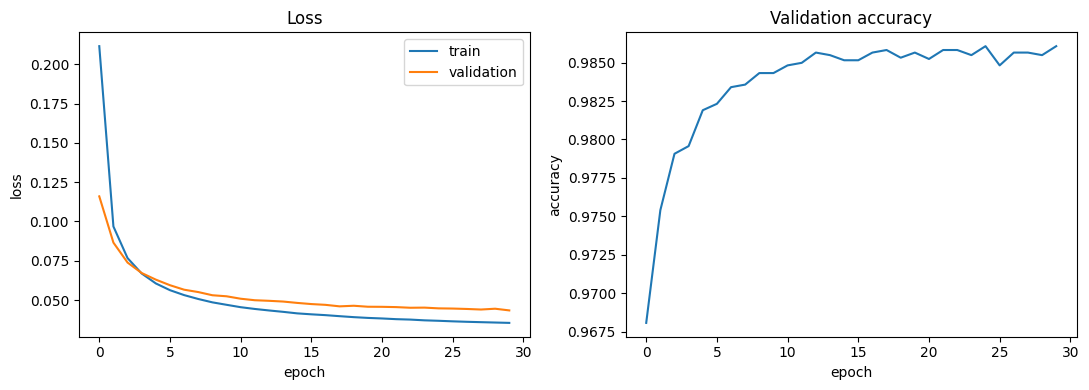

In [19]:
# Stage 5.2 - A linear classifier trained with PyTorch
torch.manual_seed(SEED)   # makes weight initialization and batch shuffling repeatable

# ----- Convert NumPy arrays into PyTorch tensors and put them on the GPU -----
# The features are small (about 170 MB for train), so they fit easily on the GPU.
Xtr = torch.tensor(X_train_s, dtype=torch.float32).to(device)
ytr = torch.tensor(y_train,   dtype=torch.float32).to(device)
Xva = torch.tensor(X_val_s,   dtype=torch.float32).to(device)
yva = torch.tensor(y_val,     dtype=torch.float32).to(device)

# A DataLoader hands us the training data in shuffled mini-batches of 256
train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=256, shuffle=True)

# ----- The model: ONE linear layer -----
# nn.Linear(768, 1) computes: score = w1*x1 + w2*x2 + ... + w768*x768 + b
# The score (called a "logit") is positive for "AI", negative for "real".
classifier = nn.Linear(768, 1).to(device)

# ----- Loss function -----
# BCEWithLogitsLoss = Binary Cross-Entropy. It measures how wrong the
# predictions are for a two-class problem. It applies the sigmoid function
# (squashes a score into a 0-1 probability) internally, which is numerically safer.
loss_fn = nn.BCEWithLogitsLoss()

# ----- Optimizer -----
# Adam updates the weights to reduce the loss.
# lr (learning rate)  : the size of each update step.
# weight_decay        : a small penalty on large weights (regularization).
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3, weight_decay=1e-4)

EPOCHS = 30   # one epoch = one full pass over the training data
history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val_loss = float("inf")
best_weights = None

for epoch in range(EPOCHS):
    # ===== Training phase =====
    classifier.train()
    running_loss = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()                 # 1) clear gradients from the last step
        logits = classifier(xb).squeeze(1)    # 2) forward pass: (256,1) -> (256,)
        loss = loss_fn(logits, yb)            # 3) measure the error
        loss.backward()                       # 4) backpropagation: compute gradients
        optimizer.step()                      # 5) update the weights
        running_loss += loss.item() * len(xb)
    train_loss = running_loss / len(Xtr)

    # ===== Validation phase =====
    # No gradients, no weight updates: we only measure performance.
    classifier.eval()
    with torch.no_grad():
        val_logits = classifier(Xva).squeeze(1)
        val_loss = loss_fn(val_logits, yva).item()
        val_pred = (val_logits > 0).float()   # logit > 0  <=>  probability > 0.5
        val_acc = (val_pred == yva).float().mean().item()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    # Keep a copy of the weights with the lowest validation loss
    # (the test set is never used to make this choice)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(classifier.state_dict())

    print(f"Epoch {epoch+1:2d}/{EPOCHS} | train loss {train_loss:.4f} | "
          f"val loss {val_loss:.4f} | val acc {val_acc:.4f}")

# Restore the best weights and save them to disk
classifier.load_state_dict(best_weights)
torch.save(best_weights, "/kaggle/working/linear_classifier.pt")

# ----- Plot the learning curves -----
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], label="validation")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].set_title("Loss")
ax[1].plot(history["val_acc"])
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].set_title("Validation accuracy")
plt.tight_layout(); plt.show()

# Stage 6: Evaluation
Evaluate on the untouched test set, run a shuffled-label control to rule out leakage, and look at the images the model gets wrong.

### 6.1 Test-set metrics
Accuracy, precision, recall, F1, ROC-AUC and confusion matrices for both models.


===== Logistic regression (C=0.1) =====
Accuracy : 0.9869  (95% CI: +/- 0.0020)
Precision: 0.9850
Recall   : 0.9888
F1-score : 0.9869
ROC-AUC  : 0.9983
              precision    recall  f1-score   support

    real (0)     0.9888    0.9850    0.9869      5997
      ai (1)     0.9850    0.9888    0.9869      5996

    accuracy                         0.9869     11993
   macro avg     0.9869    0.9869    0.9869     11993
weighted avg     0.9869    0.9869    0.9869     11993


===== PyTorch linear classifier =====
Accuracy : 0.9860  (95% CI: +/- 0.0021)
Precision: 0.9845
Recall   : 0.9875
F1-score : 0.9860
ROC-AUC  : 0.9982
              precision    recall  f1-score   support

    real (0)     0.9875    0.9845    0.9860      5997
      ai (1)     0.9845    0.9875    0.9860      5996

    accuracy                         0.9860     11993
   macro avg     0.9860    0.9860    0.9860     11993
weighted avg     0.9860    0.9860    0.9860     11993



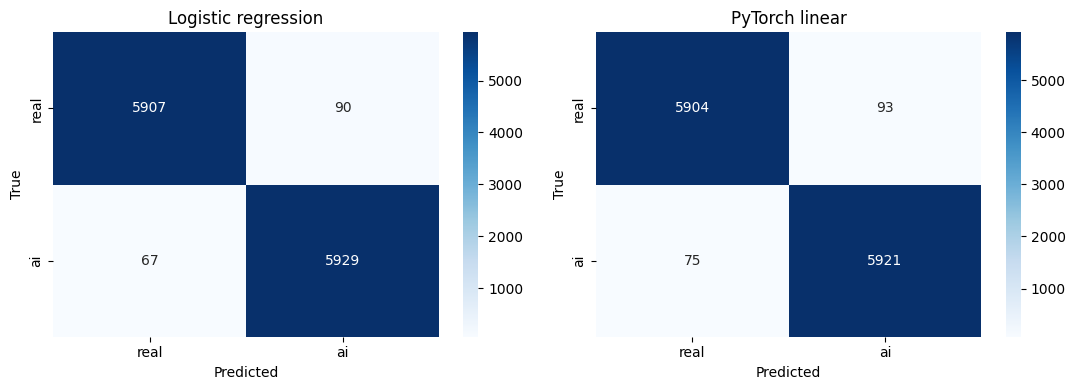

In [20]:
# Stage 6.1 - Final evaluation on the TEST set
# ----- Safety check: features and dataframe rows must be in the same order -----
# Stage 4 used shuffle=False, so row i of the features = row i of test_df.
# If this assertion passes, we can safely match predictions to image paths later.
assert (test_df["label"].values == y_test).all(), "Order mismatch between features and test_df!"

# ----- Model 1 (main model): logistic regression, C=0.1 -----
# In Stage 5.1 the variable 'clf' ended up holding the C=1.0 model (last in the loop),
# so we retrain the C=0.1 model that we selected using the VALIDATION set.
final_logreg = LogisticRegression(C=0.1, max_iter=1000)
final_logreg.fit(X_train_s, y_train)
logreg_prob = final_logreg.predict_proba(X_test_s)[:, 1]   # probability of "AI"

# ----- Model 2: the PyTorch linear classifier trained in Stage 5.2 -----
classifier.eval()
X_test_tensor = torch.tensor(X_test_s, dtype=torch.float32).to(device)
with torch.no_grad():
    logits = classifier(X_test_tensor).squeeze(1)
    # sigmoid converts the logit (any number) into a probability between 0 and 1
    torch_prob = torch.sigmoid(logits).cpu().numpy()

# ----- Helper: compute and print all metrics -----
# We treat "AI" (label 1) as the POSITIVE class.
#   Precision = of the images we called AI, how many really were AI?
#   Recall    = of the real AI images, how many did we catch?
#   F1        = the balance (harmonic mean) of precision and recall
def evaluate(name, y_true, prob):
    pred = (prob > 0.5).astype(int)              # probability > 0.5 -> predict AI
    acc = accuracy_score(y_true, pred)
    # Approximate 95% confidence interval for accuracy (normal approximation)
    ci = 1.96 * np.sqrt(acc * (1 - acc) / len(y_true))
    print(f"\n===== {name} =====")
    print(f"Accuracy : {acc:.4f}  (95% CI: +/- {ci:.4f})")
    print(f"Precision: {precision_score(y_true, pred):.4f}")
    print(f"Recall   : {recall_score(y_true, pred):.4f}")
    print(f"F1-score : {f1_score(y_true, pred):.4f}")
    print(f"ROC-AUC  : {roc_auc_score(y_true, prob):.4f}")
    print(classification_report(y_true, pred, target_names=["real (0)", "ai (1)"], digits=4))
    return pred

logreg_pred = evaluate("Logistic regression (C=0.1)", y_test, logreg_prob)
torch_pred  = evaluate("PyTorch linear classifier",   y_test, torch_prob)

# ----- Confusion matrices -----
# Rows = true class, columns = predicted class.
# Diagonal = correct predictions. Off-diagonal = mistakes.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, pred) in zip(axes, [("Logistic regression", logreg_pred),
                                   ("PyTorch linear", torch_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["real", "ai"], yticklabels=["real", "ai"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(name)
plt.tight_layout()
plt.show()

### 6.2 Control: shuffled labels
Train on scrambled labels; accuracy should be about 50%, otherwise something is leaking.

In [21]:
# Stage 6.2 - Sanity check: train on SHUFFLED labels
# If we randomly scramble the training labels, there is nothing real to learn.
# A correct pipeline must then score ~50% accuracy on validation.
# A much higher score would reveal a leakage bug.
rng = np.random.RandomState(SEED)
y_train_shuffled = rng.permutation(y_train)       # same labels, random order

control = LogisticRegression(C=0.1, max_iter=1000)
control.fit(X_train_s, y_train_shuffled)

control_acc = accuracy_score(y_val, control.predict(X_val_s))
print(f"Shuffled-label control | val accuracy: {control_acc:.4f}  (expected ~0.50)")

Shuffled-label control | val accuracy: 0.4887  (expected ~0.50)


### 6.3 Error analysis
Show the most confident mistakes (real images called AI, and AI images called real).

False positives (real -> predicted AI): 90
False negatives (AI -> predicted real): 67


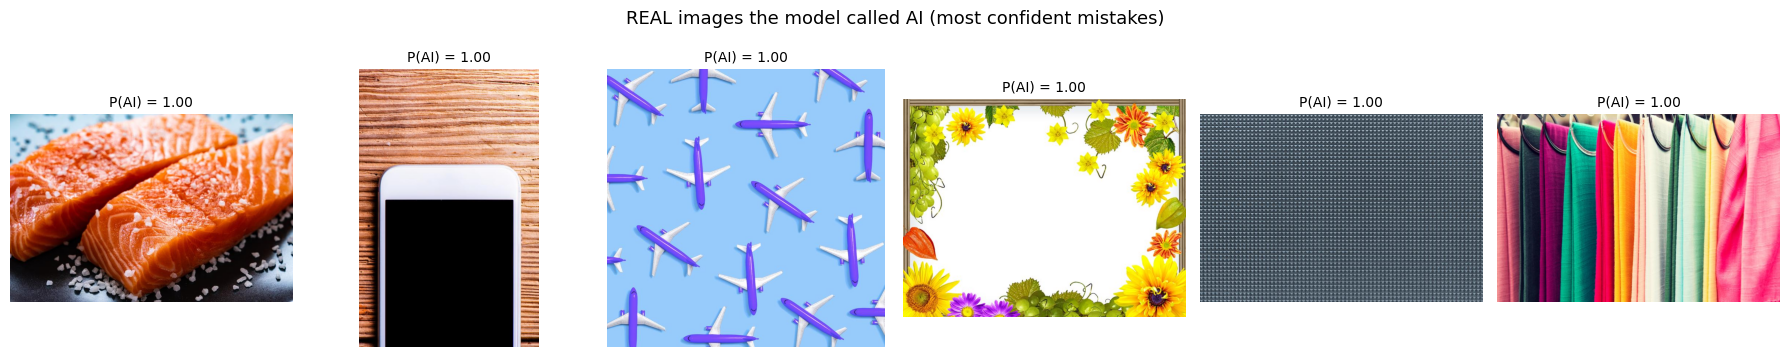

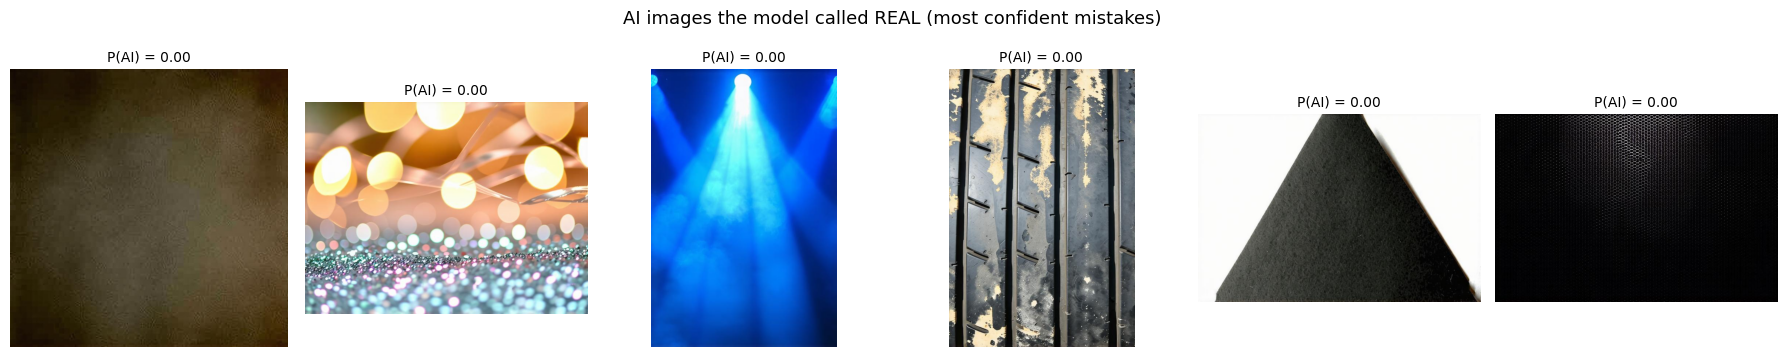

In [22]:
# Stage 6.3 - Error analysis: which images does the model get wrong?
# Attach predictions to the test table (rows are in the same order, checked in Stage 6.1)
results = test_df.reset_index(drop=True).copy()
results["prob_ai"] = logreg_prob
results["pred"] = (logreg_prob > 0.5).astype(int)

# False positive = REAL image wrongly called AI
# False negative = AI image wrongly called real
# We sort so that the most confident mistakes come first.
false_pos = results[(results["label"] == 0) & (results["pred"] == 1)].sort_values("prob_ai", ascending=False)
false_neg = results[(results["label"] == 1) & (results["pred"] == 0)].sort_values("prob_ai", ascending=True)

print("False positives (real -> predicted AI):", len(false_pos))
print("False negatives (AI -> predicted real):", len(false_neg))

def show_images(rows, title, n=6):
    n = min(n, len(rows))
    if n == 0:
        print("No images to show for:", title)
        return
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.6))
    axes = np.atleast_1d(axes)
    for ax, (_, row) in zip(axes, rows.head(n).iterrows()):
        with Image.open(row["path"]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"P(AI) = {row['prob_ai']:.2f}", fontsize=10)
        ax.axis("off")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

show_images(false_pos, "REAL images the model called AI (most confident mistakes)")
show_images(false_neg, "AI images the model called REAL (most confident mistakes)")

# Stage 7: Transfer test on CIFAKE
Test generalization: apply the trained model, **without retraining**, to CIFAKE, a different dataset of small (32x32) real and AI-generated images.

### 7.1 Load a CIFAKE sample
Take 2,000 real and 2,000 AI images from CIFAKE's test folder.

In [23]:
# Stage 7.1 - Load a sample of CIFAKE test images
CIFAKE_ROOT = "/kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/test"

rows = []
# Here the label comes from the FOLDER NAME, so there is no ambiguity:
# FAKE = AI-generated = 1,  REAL = 0. (Same convention as our main dataset.)
for folder_name, label in [("REAL", 0), ("FAKE", 1)]:
    folder = os.path.join(CIFAKE_ROOT, folder_name)
    for filename in os.listdir(folder):
        rows.append({"path": os.path.join(folder, filename), "label": label})

cifake_all = pd.DataFrame(rows)

# Take 2000 random images per class (4000 total). That is enough for a reliable
# estimate and keeps extraction fast. random_state makes it repeatable.
cifake_df = (cifake_all.groupby("label", group_keys=False)
                       .sample(2000, random_state=SEED)
                       .reset_index(drop=True))

print("CIFAKE evaluation set:", len(cifake_df), "images")
print(cifake_df["label"].value_counts().sort_index())

# Check the image size, to confirm that these are small images
print("Example image size:", Image.open(cifake_df["path"][0]).size)

CIFAKE evaluation set: 4000 images
label
0    2000
1    2000
Name: count, dtype: int64
Example image size: (32, 32)


### 7.2 Apply the trained model
Extract features, scale them with the *original* scaler and predict with the already-trained logistic regression.

In [24]:
# Stage 7.2 - Transfer test: apply our trained model to CIFAKE
# 1) Extract DINOv3 features with the SAME function and preprocessing as before
X_cifake, y_cifake = extract_features(cifake_df, "CIFAKE")

# 2) Scale with the scaler fitted on our ORIGINAL training set.
#    We deliberately do NOT refit it: the model must be tested "as it is".
X_cifake_s = scaler.transform(X_cifake)

# 3) Predict with the final logistic regression from Stage 6.1 (no retraining)
cifake_prob = final_logreg.predict_proba(X_cifake_s)[:, 1]
cifake_pred = (cifake_prob > 0.5).astype(int)

print(f"\nCIFAKE accuracy : {accuracy_score(y_cifake, cifake_pred):.4f}")
print(f"CIFAKE ROC-AUC  : {roc_auc_score(y_cifake, cifake_prob):.4f}")
print(f"Share predicted as AI: {cifake_pred.mean():.3f}  (true share is 0.500)")
print("Confusion matrix (rows = true real/ai, columns = predicted real/ai):")
print(confusion_matrix(y_cifake, cifake_pred))

Extracting CIFAKE:   0%|          | 0/63 [00:00<?, ?it/s]


CIFAKE accuracy : 0.5208
CIFAKE ROC-AUC  : 0.6790
Share predicted as AI: 0.048  (true share is 0.500)
Confusion matrix (rows = true real/ai, columns = predicted real/ai):
[[1946   54]
 [1863  137]]


# Stage 8: Results and final report
Collect all experiments in one table, then print the final report with the key findings and summary figures.

### 8.1 Results table
Collect every experiment into one table and save it as a CSV file.

In [25]:
# Stage 8.1 - Collect every experiment into one results table

# Each experiment = (name, true labels, predicted probability of AI)
experiments = [
    ("Dummy baseline (val)",            y_val,    dummy.predict_proba(X_val_s)[:, 1]),
    ("LogReg on test (main dataset)",   y_test,   logreg_prob),
    ("PyTorch linear on test",          y_test,   torch_prob),
    ("LogReg on CIFAKE (transfer)",     y_cifake, cifake_prob),
]

# Compute the metrics of each experiment (probability > 0.5 -> predicted AI)
rows = []
for name, y_true, prob in experiments:
    pred = (prob > 0.5).astype(int)
    rows.append({
        "Experiment": name,
        "Accuracy":  round(accuracy_score(y_true, pred), 4),
        "Precision": round(precision_score(y_true, pred, zero_division=0), 4),
        "Recall":    round(recall_score(y_true, pred), 4),
        "F1":        round(f1_score(y_true, pred), 4),
        "ROC-AUC":   round(roc_auc_score(y_true, prob), 4),
    })

summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

# Keep a copy of the table for the report
summary.to_csv("/kaggle/working/results_summary.csv", index=False)

                   Experiment  Accuracy  Precision  Recall     F1  ROC-AUC
         Dummy baseline (val)    0.5000     0.5000  1.0000 0.6667   0.5000
LogReg on test (main dataset)    0.9869     0.9850  0.9888 0.9869   0.9983
       PyTorch linear on test    0.9860     0.9845  0.9875 0.9860   0.9982
  LogReg on CIFAKE (transfer)    0.5208     0.7173  0.0685 0.1251   0.6790


### 8.2 Final report
Setup, splits, results, sanity checks, error counts, key findings, and the summary figures (confusion matrices, ROC curves, metric bars, learning curves).


1. PROJECT SETUP
Task               : classify images as real (0) or AI-generated (1)
Model              : facebook/dinov3-vits16-pretrain-lvd1689m
DINOv3 parameters  : 21.6 million (all FROZEN: used only to extract features)
Input size         : 224x224, normalized by the checkpoint's own processor
Features per image : 768 (CLS token 384 + mean of patch tokens 384)
Classifiers        : logistic regression (sklearn) and one linear layer (PyTorch)
Random seed        : 42

2. DATASET AND SPLITS
Main dataset   : AI vs Human Generated Dataset (labels from train.csv)
Total images   : 79950
Extra test set : CIFAKE, 4000 images (2000 real + 2000 AI, 32x32 pixels)

     Split  Images  Real (0)  AI (1)
     Train   55965     27982   27983
Validation   11992      5996    5996
      Test   11993      5997    5996

Images shared between splits (must be 0): 0

3. RESULTS TABLE
                   Experiment  Accuracy  Precision  Recall     F1  ROC-AUC
         Dummy baseline (val)    0.5000     0.5

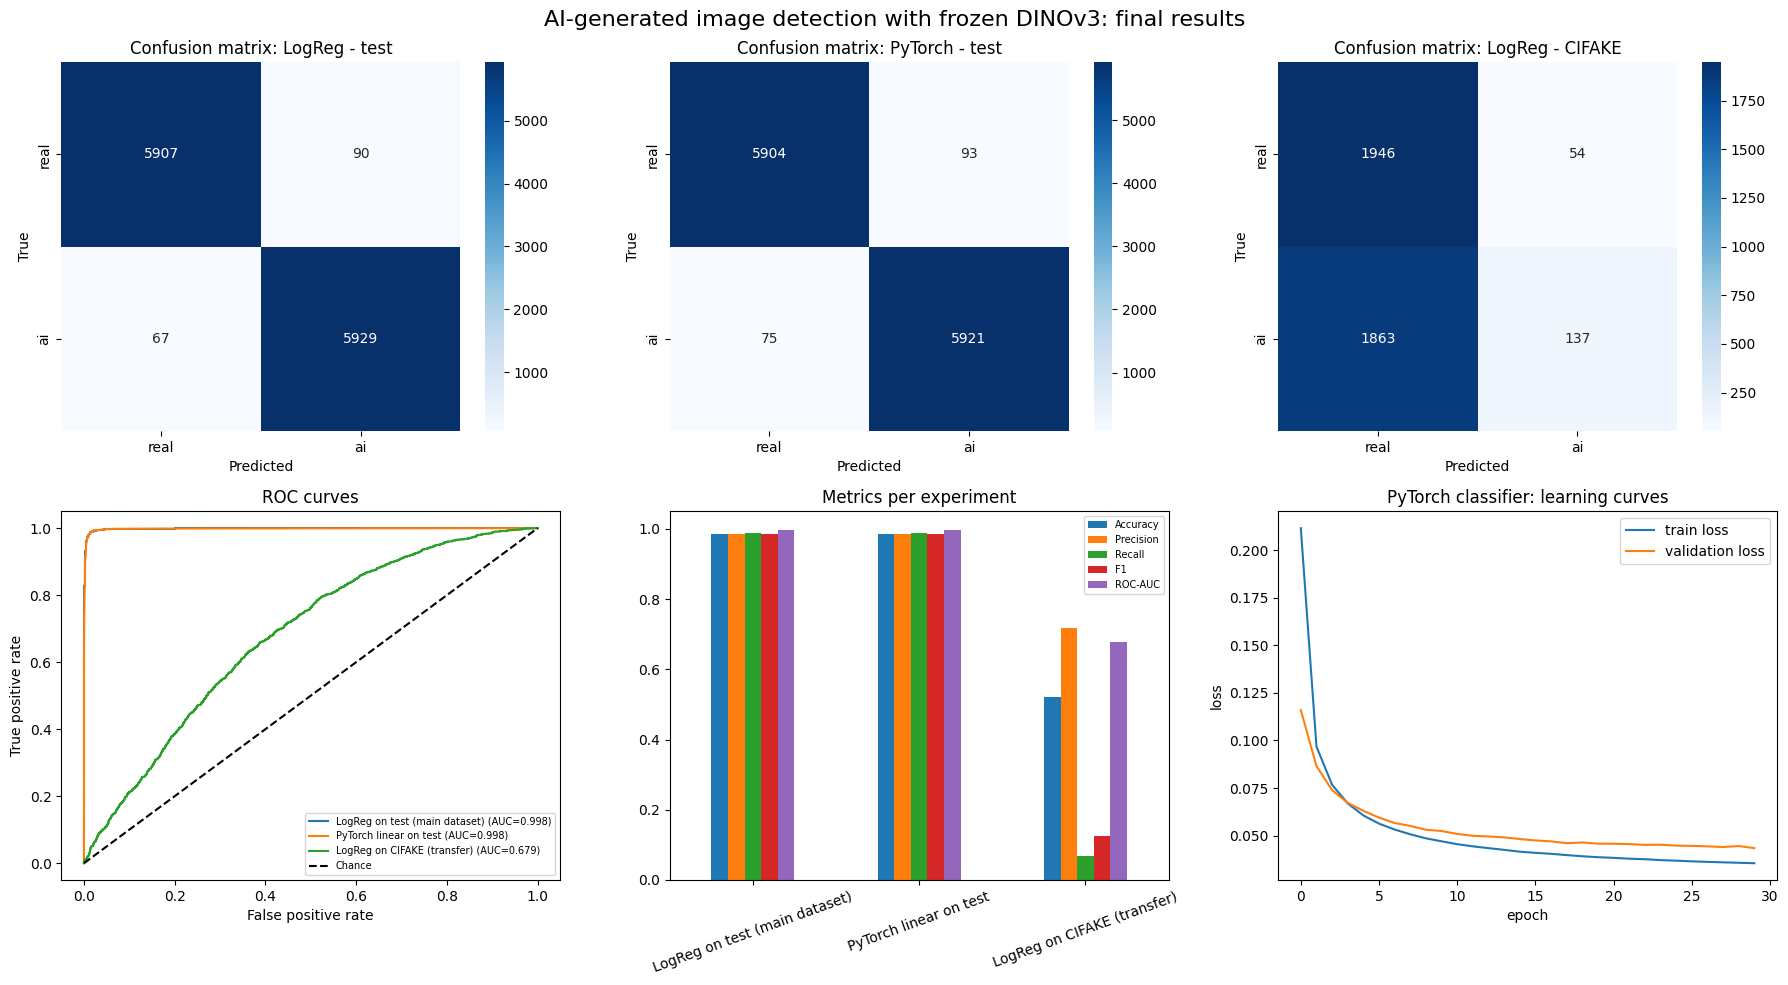

In [26]:
# Stage 8.2 - Complete project report (everything in one place)
# This cell does NOT train anything. It only collects results that
# were already computed in earlier cells and displays them in order.

# Small helper that prints a clear section title
def section(title):
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)

# ===================== 1. PROJECT SETUP =====================
section("1. PROJECT SETUP")
n_params = sum(p.numel() for p in model.parameters())   # count DINOv3 weights
print("Task               : classify images as real (0) or AI-generated (1)")
print("Model              :", MODEL_NAME)
print(f"DINOv3 parameters  : {n_params/1e6:.1f} million (all FROZEN: used only to extract features)")
print("Input size         : 224x224, normalized by the checkpoint's own processor")
print("Features per image :", X_train.shape[1], "(CLS token 384 + mean of patch tokens 384)")
print("Classifiers        : logistic regression (sklearn) and one linear layer (PyTorch)")
print("Random seed        :", SEED)

# ===================== 2. DATASET AND SPLITS =====================
section("2. DATASET AND SPLITS")
print("Main dataset   : AI vs Human Generated Dataset (labels from train.csv)")
print("Total images   :", len(df))
print("Extra test set : CIFAKE,", len(cifake_df), "images (2000 real + 2000 AI, 32x32 pixels)\n")

split_table = pd.DataFrame({
    "Split":    ["Train", "Validation", "Test"],
    "Images":   [len(d) for d in (train_df, val_df, test_df)],
    "Real (0)": [(d["label"] == 0).sum() for d in (train_df, val_df, test_df)],
    "AI (1)":   [(d["label"] == 1).sum() for d in (train_df, val_df, test_df)],
})
print(split_table.to_string(index=False))

# Re-check data leakage: the number of images shared between splits must be 0
overlap = (len(set(train_df["path"]) & set(val_df["path"]))
           + len(set(train_df["path"]) & set(test_df["path"]))
           + len(set(val_df["path"])   & set(test_df["path"])))
print("\nImages shared between splits (must be 0):", overlap)

# ===================== 3. MAIN RESULTS TABLE =====================
section("3. RESULTS TABLE")
print(summary.to_string(index=False))

# ===================== 4. SANITY CHECKS =====================
section("4. SANITY CHECKS")
print(f"Dummy baseline accuracy (val)       : {summary.iloc[0]['Accuracy']:.4f}  (expected ~0.50)")
print(f"Shuffled-label control accuracy (val): {control_acc:.4f}  (expected ~0.50 -> no leakage)")

# ===================== 5. ERROR ANALYSIS =====================
section("5. ERRORS ON THE TEST SET (logistic regression)")
print("False positives (real called AI):", len(false_pos))
print("False negatives (AI called real):", len(false_neg))
print("Total errors:", len(false_pos) + len(false_neg), "out of", len(test_df))

# ===================== 6. TRANSFER TO CIFAKE =====================
section("6. TRANSFER TEST ON CIFAKE (model NOT retrained)")
print(f"Accuracy             : {accuracy_score(y_cifake, cifake_pred):.4f}")
print(f"ROC-AUC              : {roc_auc_score(y_cifake, cifake_prob):.4f}")
print(f"Share predicted as AI: {cifake_pred.mean():.3f}  (true share = 0.500)")

# ===================== 7. KEY FINDINGS =====================
section("7. KEY FINDINGS")
res = summary.set_index("Experiment")
main_acc  = res.loc["LogReg on test (main dataset)", "Accuracy"]
main_auc  = res.loc["LogReg on test (main dataset)", "ROC-AUC"]
cif_acc   = res.loc["LogReg on CIFAKE (transfer)", "Accuracy"]
cif_auc   = res.loc["LogReg on CIFAKE (transfer)", "ROC-AUC"]
cif_rec   = res.loc["LogReg on CIFAKE (transfer)", "Recall"]

print(f"1) On the main dataset, frozen DINOv3 features + a linear classifier reach "
      f"{main_acc:.1%} accuracy (AUC {main_auc:.3f}) on a test set never used for any choice.")
print("2) The shuffled-label control stays near 50%, so the high score is not a leakage bug.")
print(f"3) The model does NOT transfer to CIFAKE: accuracy {cif_acc:.1%}, AUC {cif_auc:.3f}, "
      f"and it catches only {cif_rec:.1%} of AI images.")
print("   Possible reasons (hypotheses, not tested): CIFAKE images are 32x32 and upscaled to 224,")
print("   and they come from a different generator and different content than the main dataset.")
print("4) Conclusion: DINOv3 features separate real/AI very well INSIDE one dataset,")
print("   but this does not prove they detect AI images in general.")

# ===================== 8. FIGURES =====================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# --- Row 1: three confusion matrices (rows = true class, columns = predicted class) ---
for ax, (name, y_true, pred) in zip(axes[0], [
        ("LogReg - test",   y_test,   logreg_pred),
        ("PyTorch - test",  y_test,   torch_pred),
        ("LogReg - CIFAKE", y_cifake, cifake_pred)]):
    cm = confusion_matrix(y_true, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["real", "ai"], yticklabels=["real", "ai"])
    ax.set_title("Confusion matrix: " + name)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")

# --- ROC curves for the three real experiments (skip the dummy baseline) ---
ax = axes[1, 0]
for name, y_true, prob in experiments[1:]:
    fpr, tpr, _ = roc_curve(y_true, prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_true, prob):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves"); ax.legend(loc="lower right", fontsize=7)

# --- Bar chart comparing all metrics for each experiment ---
ax = axes[1, 1]
res.iloc[1:][["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(kind="bar", ax=ax)
ax.set_ylim(0, 1.05); ax.set_title("Metrics per experiment")
ax.set_xlabel(""); ax.tick_params(axis="x", labelrotation=20)
ax.legend(fontsize=7)

# --- Learning curves of the PyTorch classifier ---
ax = axes[1, 2]
ax.plot(history["train_loss"], label="train loss")
ax.plot(history["val_loss"], label="validation loss")
ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.set_title("PyTorch classifier: learning curves"); ax.legend()

plt.suptitle("AI-generated image detection with frozen DINOv3: final results", fontsize=16)
plt.tight_layout()
plt.savefig("/kaggle/working/final_results.png", dpi=150)   # keep a copy for your report
plt.show()

# **Stage 8: Fine-tuned DINOv3 (unfrozen backbone)**

#### Until now DINOv3 was **frozen**: it only extracted features and a small classifier was trained on top.
#### Here we train **the whole network end to end** (DINOv3 backbone + a new classification head) on the **same**
#### train / validation / test splits, and then compare it with the frozen version.

## Cache all images at 224x224 (done once)

In [27]:
# ---------------------------------------------------------------
# STAGE 8 - CELL A: Resize every image ONCE and save it to disk
# ---------------------------------------------------------------
# Why: fine-tuning passes over the training images several times (once per epoch).
# Decoding and resizing big JPEGs every time makes the CPU the bottleneck
# (feature extraction ran at only ~39 images/second). We do it once here.
import os
import time
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

CACHE_DIR = "/kaggle/temp/cache224"      # scratch space: not part of the notebook output
os.makedirs(CACHE_DIR, exist_ok=True)

# A Dataset that only opens an image, resizes it to 224x224 and returns raw pixels.
# Pixels are stored as uint8 (0-255): 4x smaller than float32.
# Normalization (mean/std) is applied later, on the GPU, during training.
class ResizeDataset(Dataset):
    def __init__(self, dataframe):
        self.paths = dataframe["path"].tolist()

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        # Same target size and resampling (bilinear, resample=2) as the DINOv3 processor
        img = img.resize((224, 224), Image.BILINEAR)
        return torch.from_numpy(np.asarray(img).copy())      # (224, 224, 3) uint8


def cache_split(split_df, split_name, batch_size=256, num_workers=4):
    out_path = os.path.join(CACHE_DIR, f"images_{split_name}.npy")
    done_path = out_path + ".done"
    if os.path.exists(done_path):                 # already cached (e.g. after a re-run)
        print(f"{split_name}: already cached, skipping.")
        return

    # open_memmap creates a .npy file on disk that we fill batch by batch,
    # so the full array (several GB) never has to fit in RAM.
    arr = np.lib.format.open_memmap(out_path, mode="w+", dtype=np.uint8,
                                    shape=(len(split_df), 224, 224, 3))
    loader = DataLoader(ResizeDataset(split_df), batch_size=batch_size,
                        shuffle=False,            # keep the SAME order as split_df
                        num_workers=num_workers)
    pos = 0
    for batch in tqdm(loader, desc=f"Caching {split_name}"):
        arr[pos:pos + len(batch)] = batch.numpy()
        pos += len(batch)
    arr.flush()

    np.save(os.path.join(CACHE_DIR, f"labels_{split_name}.npy"),
            split_df["label"].values.astype(np.int64))
    open(done_path, "w").close()                  # marker: this split is complete
    print(f"{split_name}: saved {arr.shape} ({arr.nbytes / 1e9:.2f} GB)")


start = time.time()
for name, split_df in [("val", val_df), ("test", test_df), ("cifake", cifake_df), ("train", train_df)]:
    cache_split(split_df, name)
print(f"\nTotal caching time: {(time.time() - start) / 60:.1f} minutes")

# ----- Sanity checks -----
check = np.load(os.path.join(CACHE_DIR, "images_val.npy"), mmap_mode="r")
labels_check = np.load(os.path.join(CACHE_DIR, "labels_val.npy"))
print("Cached val array:", check.shape, check.dtype)
print("Labels match val_df (same order):", (labels_check == val_df["label"].values).all())

# Compare one cached image with what the official processor produces for the same file
mean = torch.tensor(processor.image_mean).view(3, 1, 1)
std = torch.tensor(processor.image_std).view(3, 1, 1)
ref = processor(images=Image.open(val_df["path"].iloc[0]).convert("RGB"),
                return_tensors="pt")["pixel_values"][0]
mine = (torch.from_numpy(np.array(check[0])).permute(2, 0, 1).float() / 255.0 - mean) / std
print("Max abs difference vs the processor (small = good):", (ref - mine).abs().max().item())

Caching val:   0%|          | 0/47 [00:00<?, ?it/s]

val: saved (11992, 224, 224, 3) (1.81 GB)


Caching test:   0%|          | 0/47 [00:00<?, ?it/s]

test: saved (11993, 224, 224, 3) (1.81 GB)


Caching cifake:   0%|          | 0/16 [00:00<?, ?it/s]

cifake: saved (4000, 224, 224, 3) (0.60 GB)


Caching train:   0%|          | 0/219 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2c4cdeb380>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
Exception ignored in:   File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e2c4cdeb380>    assert self._parent_pid == os.getpid(), 'can only test a child process'

AssertionErrorTraceback (most recent call last):
:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
can only test a child process
    Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2c4cdeb380>self._shutdown_workers()
Traceback (most recent call last):

  File "/usr/local/lib/pyt

train: saved (55965, 224, 224, 3) (8.42 GB)

Total caching time: 8.6 minutes
Cached val array: (11992, 224, 224, 3) uint8
Labels match val_df (same order): True
Max abs difference vs the processor (small = good): 0.017506778240203857


## Dataset, model and training settings

In [28]:
# ---------------------------------------------------------------
# STAGE 8 - CELL B: Dataset from the cache + the fine-tuning model
# ---------------------------------------------------------------
import math
import torch.nn as nn
from torch.optim.lr_scheduler import LambdaLR

# ===== Settings (change them here) =====
FT_EPOCHS       = 3        # full passes over the training set
FT_BATCH        = 64       # images per step (fits a T4 with mixed precision)
BACKBONE_LR     = 2e-5     # SMALL learning rate for the pretrained DINOv3 weights
HEAD_LR         = 1e-3     # larger learning rate for the new, randomly initialized head
N_FROZEN_BLOCKS = 0        # 0 = fine-tune everything. Example: 8 = freeze the patch
                           # embedding + first 8 of the 12 transformer blocks (faster).
FT_WEIGHTS      = "/kaggle/working/dinov3_finetuned.pt"

# ----- Dataset that reads the cached uint8 images -----
class CachedDataset(Dataset):
    def __init__(self, split_name):
        self.img_path = os.path.join(CACHE_DIR, f"images_{split_name}.npy")
        self.labels = np.load(os.path.join(CACHE_DIR, f"labels_{split_name}.npy"))
        self.images = None                          # opened lazily inside each worker process

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        if self.images is None:
            self.images = np.load(self.img_path, mmap_mode="r")
        img = torch.from_numpy(np.array(self.images[idx]))      # (224, 224, 3) uint8
        return img, torch.tensor(self.labels[idx], dtype=torch.float32)

# ----- Preprocessing on the GPU: uint8 -> float, normalize, (train only) random flip -----
MEAN = torch.tensor(processor.image_mean, device=device).view(1, 3, 1, 1)
STD  = torch.tensor(processor.image_std,  device=device).view(1, 3, 1, 1)

def prepare_batch(xb, train):
    x = xb.to(device, non_blocking=True).permute(0, 3, 1, 2).float() / 255.0   # (B,3,224,224) in [0,1]
    if train:
        # Data augmentation: each image has a 50% chance of being mirrored left-right.
        # We use ONLY this mild augmentation: blur, noise or heavy JPEG changes could
        # destroy the very artifacts that tell real and AI images apart.
        flip = torch.rand(x.shape[0], device=device) < 0.5
        x = torch.where(flip.view(-1, 1, 1, 1), x.flip(3), x)
    return (x - MEAN) / STD

# ----- The model: DINOv3 backbone + linear head (same 768 features as the frozen version) -----
class FineTunedDINO(nn.Module):
    def __init__(self, model_name):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(model_name)   # a NEW copy: the frozen `model` is untouched
        hidden = self.backbone.config.hidden_size               # 384 for ViT-S
        self.n_special = 1 + self.backbone.config.num_register_tokens   # CLS + register tokens
        self.head = nn.Linear(2 * hidden, 1)                    # 768 -> 1 logit (positive = AI)

    def forward(self, pixel_values):
        tokens = self.backbone(pixel_values=pixel_values).last_hidden_state
        cls_token = tokens[:, 0, :]
        patch_mean = tokens[:, self.n_special:, :].mean(dim=1)
        features = torch.cat([cls_token, patch_mean], dim=1)    # same recipe as Stage 3
        return self.head(features).squeeze(1)

torch.manual_seed(SEED)
ft_model = FineTunedDINO(MODEL_NAME).to(device)

# Optionally freeze the early layers (only when N_FROZEN_BLOCKS > 0)
if N_FROZEN_BLOCKS > 0:
    for p in ft_model.backbone.embeddings.parameters():
        p.requires_grad = False
    for block in ft_model.backbone.layer[:N_FROZEN_BLOCKS]:
        for p in block.parameters():
            p.requires_grad = False

n_total = sum(p.numel() for p in ft_model.parameters())
ft_n_trainable = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)
print(f"Parameters: {n_total / 1e6:.1f} M total | {ft_n_trainable / 1e6:.1f} M trainable")

# ----- Optimizer: AdamW with two learning rates -----
# Weight decay is applied to weight matrices only (not to biases / norm / layer-scale vectors).
decay, no_decay = [], []
for p in ft_model.backbone.parameters():
    if p.requires_grad:
        (no_decay if p.ndim <= 1 else decay).append(p)
ft_optimizer = torch.optim.AdamW([
    {"params": decay,                       "lr": BACKBONE_LR, "weight_decay": 0.05},
    {"params": no_decay,                    "lr": BACKBONE_LR, "weight_decay": 0.0},
    {"params": ft_model.head.parameters(),  "lr": HEAD_LR,     "weight_decay": 1e-4},
])
ft_loss_fn = nn.BCEWithLogitsLoss()
ft_grad_scaler = torch.amp.GradScaler("cuda")     # keeps float16 gradients from underflowing

# ----- DataLoaders -----
ft_train_loader = DataLoader(CachedDataset("train"), batch_size=FT_BATCH, shuffle=True,
                             num_workers=2, pin_memory=True, drop_last=True)
ft_val_loader   = DataLoader(CachedDataset("val"), batch_size=128, shuffle=False,
                             num_workers=2, pin_memory=True)

# ----- Learning-rate schedule: short warm-up, then cosine decay to 0 -----
ft_total_steps = FT_EPOCHS * len(ft_train_loader)
ft_warmup = max(1, int(0.05 * ft_total_steps))
def lr_lambda(step):
    if step < ft_warmup:
        return (step + 1) / ft_warmup
    progress = (step - ft_warmup) / max(1, ft_total_steps - ft_warmup)
    return 0.5 * (1 + math.cos(math.pi * progress))
ft_scheduler = LambdaLR(ft_optimizer, lr_lambda)

print(f"Steps per epoch: {len(ft_train_loader)} | total steps: {ft_total_steps}")

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Parameters: 21.6 M total | 21.6 M trainable
Steps per epoch: 874 | total steps: 2622


## Quick speed test (20 steps, no weight update)

In [29]:
# ---------------------------------------------------------------
# STAGE 8 - CELL C: Measure the training speed BEFORE the full run
# ---------------------------------------------------------------
# We run forward + backward on a few batches WITHOUT updating the weights,
# only to estimate how long one epoch will take.
ft_model.train()
it = iter(ft_train_loader)
n_warm, n_timed = 5, 20

for step in range(n_warm + n_timed):
    if step == n_warm:                          # start the clock after the warm-up steps
        torch.cuda.synchronize()
        t0 = time.time()
    xb, yb = next(it)
    x, y = prepare_batch(xb, train=True), yb.to(device)
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        logits = ft_model(x)
    loss = ft_loss_fn(logits.float(), y)
    loss.backward()
    ft_optimizer.zero_grad(set_to_none=True)    # discard the gradients: no update

torch.cuda.synchronize()
elapsed = time.time() - t0
speed = n_timed * FT_BATCH / elapsed
print(f"Training speed : {speed:.0f} images/second")
print(f"One epoch      : about {len(ft_train_loader) * FT_BATCH / speed / 60:.1f} minutes")
print(f"{FT_EPOCHS} epochs        : about {FT_EPOCHS * len(ft_train_loader) * FT_BATCH / speed / 60:.1f} minutes")
print(f"Peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

Training speed : 257 images/second
One epoch      : about 3.6 minutes
3 epochs        : about 10.9 minutes
Peak GPU memory: 3.2 GB


## Fine-tune the whole model

In [30]:
# ---------------------------------------------------------------
# STAGE 8 - CELL D: Training loop (train + validation at every epoch)
# ---------------------------------------------------------------
# Evaluation helper: returns loss, accuracy, probabilities and labels for a DataLoader
@torch.no_grad()
def eval_loader(loader):
    ft_model.eval()
    all_logits, all_labels = [], []
    for xb, yb in loader:
        x = prepare_batch(xb, train=False)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = ft_model(x)
        all_logits.append(logits.float().cpu())
        all_labels.append(yb)
    logits = torch.cat(all_logits)
    labels = torch.cat(all_labels)
    loss = ft_loss_fn(logits, labels).item()
    acc = ((logits > 0).float() == labels).float().mean().item()
    return loss, acc, torch.sigmoid(logits).numpy(), labels.numpy()

ft_history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val_loss = float("inf")
train_start = time.time()

for epoch in range(FT_EPOCHS):
    # ===== Training phase =====
    ft_model.train()
    running_loss, seen = 0.0, 0
    for xb, yb in tqdm(ft_train_loader, desc=f"Epoch {epoch + 1}/{FT_EPOCHS}"):
        x, y = prepare_batch(xb, train=True), yb.to(device)

        with torch.autocast(device_type="cuda", dtype=torch.float16):   # mixed precision
            logits = ft_model(x)
        loss = ft_loss_fn(logits.float(), y)

        ft_optimizer.zero_grad(set_to_none=True)
        ft_grad_scaler.scale(loss).backward()                  # backpropagation (scaled)
        ft_grad_scaler.unscale_(ft_optimizer)
        torch.nn.utils.clip_grad_norm_(ft_model.parameters(), 1.0)   # avoid exploding updates
        ft_grad_scaler.step(ft_optimizer)                      # update the weights
        ft_grad_scaler.update()
        ft_scheduler.step()                                    # move along the LR schedule

        running_loss += loss.item() * len(xb)
        seen += len(xb)
    train_loss = running_loss / seen

    # ===== Validation phase =====
    val_loss, val_acc, _, _ = eval_loader(ft_val_loader)
    ft_history["train_loss"].append(train_loss)
    ft_history["val_loss"].append(val_loss)
    ft_history["val_acc"].append(val_acc)

    # Keep the weights with the lowest VALIDATION loss (the test set is never used here)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(ft_model.state_dict(), FT_WEIGHTS)
        tag = "  <- best so far, saved"
    else:
        tag = ""
    print(f"Epoch {epoch + 1}/{FT_EPOCHS} | train loss {train_loss:.4f} | "
          f"val loss {val_loss:.4f} | val acc {val_acc:.4f} | "
          f"elapsed {(time.time() - train_start) / 60:.1f} min{tag}")

ft_train_minutes = (time.time() - train_start) / 60
print(f"\nTotal fine-tuning time: {ft_train_minutes:.1f} minutes")

Epoch 1/3:   0%|          | 0/874 [00:00<?, ?it/s]

Epoch 1/3 | train loss 0.0788 | val loss 0.0076 | val acc 0.9979 | elapsed 4.3 min  <- best so far, saved


Epoch 2/3:   0%|          | 0/874 [00:00<?, ?it/s]

Epoch 2/3 | train loss 0.0017 | val loss 0.0047 | val acc 0.9990 | elapsed 9.2 min  <- best so far, saved


Epoch 3/3:   0%|          | 0/874 [00:00<?, ?it/s]

Epoch 3/3 | train loss 0.0002 | val loss 0.0049 | val acc 0.9988 | elapsed 13.5 min

Total fine-tuning time: 13.5 minutes


## Frozen vs fine-tuned: comparison

In [32]:
# ---------------------------------------------------------------
# STAGE 8 - CELL F: Frozen vs fine-tuned (same splits, same metrics)
# ---------------------------------------------------------------
from sklearn.metrics import precision_score, recall_score, f1_score, roc_curve

comparison = [
    # (name, true labels, probability of AI)
    ("Frozen + LogReg (test)",          y_test,   logreg_prob),
    ("Frozen + PyTorch linear (test)",  y_test,   torch_prob),
    ("Fine-tuned DINOv3 (test)",        y_test,   ft_test_prob),
    ("Frozen + LogReg (CIFAKE)",        y_cifake, cifake_prob),
    ("Fine-tuned DINOv3 (CIFAKE)",      y_cifake, ft_cifake_prob),
]

rows = []
for name, y_true, prob in comparison:
    pred = (prob > 0.5).astype(int)
    rows.append({
        "Model / dataset": name,
        "Accuracy":  round(accuracy_score(y_true, pred), 4),
        "Precision": round(precision_score(y_true, pred, zero_division=0), 4),
        "Recall":    round(recall_score(y_true, pred), 4),
        "F1":        round(f1_score(y_true, pred), 4),
        "ROC-AUC":   round(roc_auc_score(y_true, prob), 4),
        "Errors":    int((pred != y_true).sum()),
    })
compare_df = pd.DataFrame(rows)
print(compare_df.to_string(index=False))
compare_df.to_csv("/kaggle/working/results_frozen_vs_finetuned.csv", index=False)

print(f"\nTrainable parameters : frozen = linear head only (769) | fine-tuned = {ft_n_trainable / 1e6:.1f} M")
print(f"Fine-tuning time     : {ft_train_minutes:.1f} minutes")

# ----- Figures: ROC on test, ROC on CIFAKE, learning curves -----
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, group, title in [(axes[0], comparison[:3], "ROC - main test set"),
                         (axes[1], comparison[3:], "ROC - CIFAKE transfer")]:
    for name, y_true, prob in group:
        fpr, tpr, _ = roc_curve(y_true, prob)
        ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_true, prob):.3f})")
    ax.plot([0, 1], [0, 1], "k--", label="Chance")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(title); ax.legend(loc="lower right", fontsize=7)

axes[2].plot(range(1, FT_EPOCHS + 1), ft_history["train_loss"], marker="o", label="train loss")
axes[2].plot(range(1, FT_EPOCHS + 1), ft_history["val_loss"], marker="o", label="validation loss")
axes[2].set_xlabel("epoch"); axes[2].set_ylabel("loss")
axes[2].set_title("Fine-tuning: learning curves"); axes[2].legend()
plt.tight_layout()
plt.savefig("/kaggle/working/frozen_vs_finetuned.png", dpi=150)
plt.show()

NameError: name 'ft_test_prob' is not defined